# 02. Grey Wolf Optimization

**Grey Wolf Optimizer (GWO)** dipakai untuk mencari nilai minimum suatu fungsi dengan menggerakkan sekumpulan kandidat solusi secara bersamaan. Idenya terinspirasi dari kawanan serigala abu-abu di alam yang hidup berkelompok, memiliki hierarki pemimpin, dan bekerja sama mengepung mangsa.

Dalam masalah optimasi, **mangsa** mewakili solusi terbaik yang sedang dicari, **satu serigala** adalah satu kandidat solusi berupa vektor koordinat $\mathbf{x}$, dan **populasi** adalah seluruh titik tebakan yang digerakkan bersama. Kualitas tiap kandidat diukur dari nilai fungsi tujuan $f(\mathbf{x})$ (disebut *fitness*). GWO tidak membutuhkan **gradien** atau turunan fungsi — cukup nilai skor dari setiap titik, lalu tiga kandidat terbaik sejauh ini dipakai untuk mengarahkan langkah berikutnya. Karena prosesnya memakai bilangan acak, satu kali percobaan belum menjamin langsung ketemu minimum global.

Praktikum ini menerjemahkan alur slide 9–13 `GWO_Materi_Kuliah.pdf` ke kode NumPy, mulai dari inisialisasi populasi sampai `return X_alpha`, lalu mengecek hasil hitung satu iterasi. Setelah alur dasarnya jalan, kita bandingkan variasi aturan pemimpin dengan library **MEALPY** dan mencoba teknik **penalti** untuk masalah berkendala seperti di slide 17. Fungsi uji Sphere dan Rastrigin melanjutkan fungsi yang sama dari modul PSO.

## Setup

**Lokal.** Siapkan dan aktifkan virtual environment Python 3.10–3.12 yang terpisah dari modul PSO. Pemisahan ini diperlukan karena MEALPY 3.0.3 meminta NumPy $\le 1.26.0$, sedangkan modul PSO memakai NumPy 2. Jalankan perintah berikut di environment GWO, lalu buka notebook ini.

```bash
python -m pip install "mealpy==3.0.3" "jupyterlab>=4"
python -m jupyterlab
```

**Google Colab.** Kalau runtime memakai Python 3.10–3.12, jalankan `%pip install mealpy==3.0.3` di sel baru, restart runtime, lalu jalankan notebook dari atas sampai bawah. Kalau versi Python-nya berbeda, pakai setup lokal di atas. Notebook ini berdiri sendiri dan tidak butuh file dataset atau skrip tambahan.

In [1]:
from platform import python_version

import matplotlib.pyplot as plt
import mealpy
import numpy as np
from IPython.display import Markdown, display
from mealpy import FloatVar, GWO

print(f"Python {python_version()} | NumPy {np.__version__} | MEALPY {mealpy.__version__}")

Python 3.10.20 | NumPy 1.26.0 | MEALPY 3.0.3


## 1. Masalah minimisasi

Tujuan kita adalah mencari vektor koordinat $\mathbf{x}^*$ yang menghasilkan nilai fungsi tujuan $f(\mathbf{x}^*)$ sekecil mungkin, dengan tiap koordinat $x_j$ tetap berada di dalam batas ruang pencarian (*bounds*) $\ell_j \le x_j \le u_j$.

Untuk latihan, kita pakai dua **fungsi uji** (*benchmark*) yang jawaban aslinya sudah diketahui: **Sphere** dan **Rastrigin**. Keduanya sama-sama memiliki **minimum global** (titik paling rendah di seluruh ruang pencarian) di pusat $\mathbf{0}$ dengan skor $f(\mathbf{0})=0$. Informasi ini kita pakai untuk mengecek hasil kerja algoritma saja, bukan diberikan ke GWO sebagai jawaban. Bedanya ada di bentuk permukaannya: Sphere mulus dengan satu lembah, sedangkan Rastrigin bergelombang dengan banyak **minimum lokal** — yaitu cekungan kecil yang lebih rendah dari titik di sekitarnya, sehingga mudah menjebak algoritma sebelum mencapai pusat.

| Fungsi | Rumus | Batas per koordinat | Bentuk |
| --- | --- | --- | --- |
| Sphere | $\sum_{j=1}^{d} x_j^2$ | $[-5.12,5.12]$ | Satu lembah |
| Rastrigin | $10d + \sum_{j=1}^{d}(x_j^2 - 10\cos(2\pi x_j))$ | $[-5.12,5.12]$ | Banyak minimum lokal |

Di kode bawah, kedua fungsi bisa menerima satu titik berbentuk `(dimensi,)` ataupun sekumpulan titik berbentuk tabel `(jumlah_titik, dimensi)`, di mana satu baris mewakili satu serigala. Parameter `axis=-1` menjumlahkan sepanjang koordinat per baris, sehingga 24 baris langsung menghasilkan 24 skor terpisah tanpa mencampur semua kandidat.

Plot di Sel 5 menampilkan permukaan 3D dan irisan 1D kedua fungsi supaya perbedaan satu lembah Sphere dan banyak minimum lokal Rastrigin terlihat langsung.

In [2]:
BOUNDS = (-5.12, 5.12)


def sphere(x):
    return np.sum(x**2, axis=-1)


def rastrigin(x):
    return np.sum(x**2 + 10 * (1 - np.cos(2 * np.pi * x)), axis=-1)

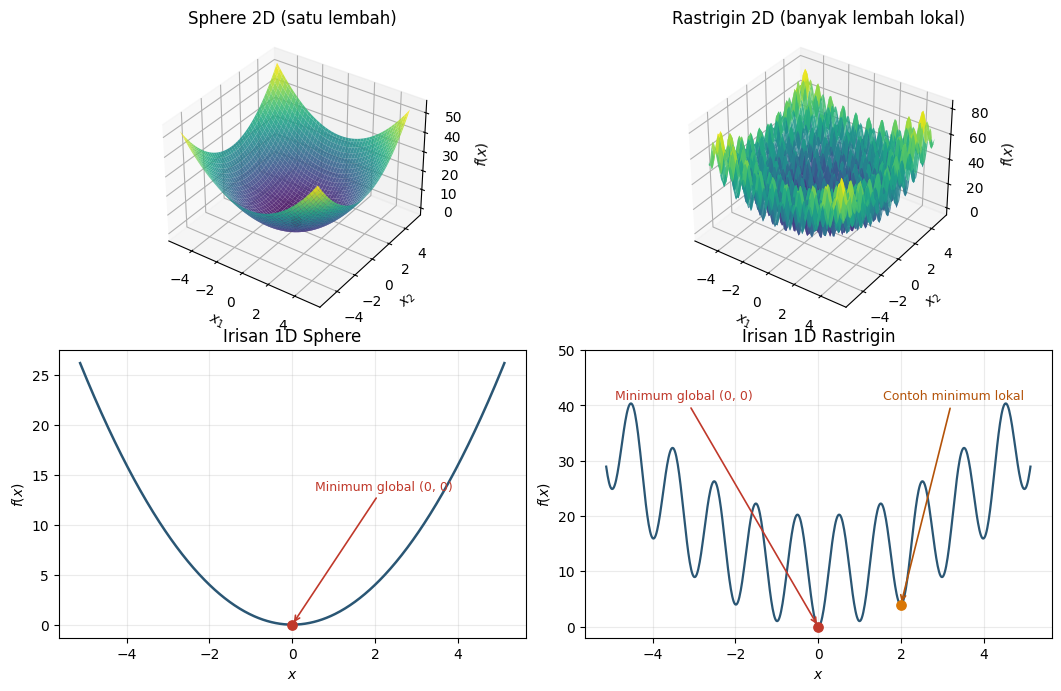

In [3]:
u_surf = np.linspace(*BOUNDS, 90)
x_s, y_s = np.meshgrid(u_surf, u_surf)
pts_s = np.stack((x_s, y_s), axis=-1)
z_sphere = sphere(pts_s)
z_rastrigin = rastrigin(pts_s)

u_line = np.linspace(*BOUNDS, 600)
y_sphere_1d = sphere(u_line[:, None])
y_rastrigin_1d = rastrigin(u_line[:, None])

local_mask = (u_line > 1.5) & (u_line < 2.5)
local_idx = np.argmin(y_rastrigin_1d[local_mask])
x_local = u_line[local_mask][local_idx]
y_local = y_rastrigin_1d[local_mask][local_idx]

fig = plt.figure(figsize=(10.5, 6.8), layout="constrained")
ax1 = fig.add_subplot(2, 2, 1, projection="3d")
ax1.plot_surface(x_s, y_s, z_sphere, cmap="viridis", alpha=0.88, linewidth=0, antialiased=True)
ax1.scatter([0], [0], [0], color="#c0392b", s=45, depthshade=False)
ax1.set(xlabel="$x_1$", ylabel="$x_2$", zlabel="$f(x)$", title="Sphere 2D (satu lembah)")
ax1.view_init(elev=34, azim=-55)

ax2 = fig.add_subplot(2, 2, 2, projection="3d")
ax2.plot_surface(x_s, y_s, z_rastrigin, cmap="viridis", alpha=0.88, linewidth=0, antialiased=True)
ax2.scatter([0], [0], [0], color="#c0392b", s=45, depthshade=False)
ax2.set(xlabel="$x_1$", ylabel="$x_2$", zlabel="$f(x)$", title="Rastrigin 2D (banyak lembah lokal)")
ax2.view_init(elev=34, azim=-55)

ax3 = fig.add_subplot(2, 2, 3)
ax3.plot(u_line, y_sphere_1d, color="#2a5674", lw=1.8)
ax3.scatter([0], [0], color="#c0392b", s=45, zorder=5)
ax3.annotate(
    "Minimum global (0, 0)",
    xy=(0, 0),
    xytext=(0.55, 13.5),
    arrowprops={"arrowstyle": "->", "color": "#c0392b", "lw": 1.2},
    color="#c0392b",
    fontsize=9,
)
ax3.set(xlabel="$x$", ylabel="$f(x)$", title="Irisan 1D Sphere")
ax3.grid(alpha=0.25)

ax4 = fig.add_subplot(2, 2, 4)
ax4.plot(u_line, y_rastrigin_1d, color="#2a5674", lw=1.6)
ax4.scatter([0], [0], color="#c0392b", s=45, zorder=5)
ax4.scatter([x_local], [y_local], color="#d97706", s=45, zorder=5)
ax4.annotate(
    "Minimum global (0, 0)",
    xy=(0, 0),
    xytext=(-4.9, 41.0),
    arrowprops={"arrowstyle": "->", "color": "#c0392b", "lw": 1.2},
    color="#c0392b",
    fontsize=9,
)
ax4.annotate(
    "Contoh minimum lokal",
    xy=(x_local, y_local),
    xytext=(1.55, 41.0),
    arrowprops={"arrowstyle": "->", "color": "#b45309", "lw": 1.2},
    color="#b45309",
    fontsize=9,
)
ax4.set(xlabel="$x$", ylabel="$f(x)$", ylim=(-2, 50), title="Irisan 1D Rastrigin")
ax4.grid(alpha=0.25)
plt.show()

## 2. Dari pseudocode slide 13 ke pipeline

```mermaid
flowchart TD
    p1["P1 · Inisialisasi populasi"] --> p2["P2 · Siapkan a, A, C"]
    p2 --> p3["P3 · Nilai populasi awal dan pilih α, β, δ"]
    p3 --> p4["P4 · Perbarui posisi"]
    p4 --> p5["P5 · Perbarui a, A, C"]
    p5 --> p6["P6 · Nilai posisi baru"]
    p6 --> p7["P7 · Perbarui α, β, δ"]
    p7 --> p8["P8 · Tambah iterasi dan laporkan alpha"]
    p8 --> p9{"P9 · Sudah T iterasi?"}
    p9 -->|"Tidak, pakai skor P6 dan pemimpin P7"| p4
    p9 -->|"Ya"| selesai(["Return Xα"])
```

### P1–P3 | Bangun dan nilai populasi awal

Sebar $N$ posisi serigala secara acak di dalam batas sebagai populasi awal (P1), lalu siapkan koefisien gerak pertama dengan parameter kontrol $a=2$ (P2). Setelah itu hitung **fitness** — skor fungsi tujuan — untuk seluruh anggota (P3). Pada minimisasi, tiga skor terkecil langsung mengisi hierarki pemimpin kawanan: **alpha ($\alpha$)** sebagai terbaik pertama, **beta ($\beta$)** terbaik kedua, dan **delta ($\delta$)** terbaik ketiga. Sisa anggota lainnya disebut **omega ($\omega$)**. Peringkat ini bisa berubah di tiap iterasi saat ada kandidat yang menemukan skor lebih kecil.

### P4 | Perbarui posisi

Dalam satu iterasi, seluruh anggota digerakkan memakai tiga pemimpin yang sama. Tiga usulan posisi di bawah dipakai untuk menghitung posisi baru satu anggota, bukan untuk langsung mengganti pemimpin — pemilihan pemimpin baru dilakukan di P7.

Untuk serigala di posisi $\mathbf{x}$, tiap pemimpin $k \in \{\alpha,\beta,\delta\}$ menghasilkan satu usulan $\mathbf{y}_k$. Simbol $\odot$ berarti perkalian per koordinat. Bilangan acak $\mathbf{r}_{1,k}$ dan $\mathbf{r}_{2,k}$ diambil terpisah dari distribusi seragam $U[0,1)$ untuk tiap anggota, pemimpin, dan koordinat supaya variasi langkah antar serigala tidak seragam.

$$
\begin{aligned}
\mathbf{A}_k &= 2a\mathbf{r}_{1,k}-a, &\mathbf{C}_k &= 2\mathbf{r}_{2,k} \qquad \text{(3.3–3.4)}, \\
\mathbf{D}_k &= \left|\mathbf{C}_k \odot \mathbf{x}_k - \mathbf{x}\right|, &
\mathbf{y}_k &= \mathbf{x}_k - \mathbf{A}_k \odot \mathbf{D}_k \qquad \text{(3.5–3.6)}, \\
\mathbf{x}_{\mathrm{baru}} &= \frac{\mathbf{y}_\alpha + \mathbf{y}_\beta + \mathbf{y}_\delta}{3}
\qquad \text{(3.7)}.
\end{aligned}
$$

Singkatnya, $\mathbf{D}_k$ adalah jarak antara serigala dan posisi pemimpin yang sudah diberi bobot acak $\mathbf{C}_k$, lalu $\mathbf{y}_k$ menggeser posisi dari pemimpin sejauh $\mathbf{A}_k \odot \mathbf{D}_k$. Posisi baru serigala diambil dari rata-rata ketiga usulan tersebut.

### P5 | Siapkan koefisien iterasi berikutnya

Parameter $a$ diturunkan secara linear dari $2$ ke $0$ memakai $a_j=2(1-j/(T-1))$ untuk iterasi $j=0,\ldots,T-1$ saat $T>1$. Pembagi $T-1$ memastikan gerakan pertama persis memakai $a=2$ dan gerakan terakhir memakai $a=0$ (khusus demo 1 gerakan, dipakai $a=2$). P2 menyiapkan koefisien untuk langkah pertama, sedangkan P5 menyiapkan koefisien untuk langkah berikutnya selama iterasi belum selesai.

Sesuai slide 11, rentang nilai $A$ selalu berada di $[-a,a]$. Saat $a>1$ di paruh awal, $|A|$ bisa melebihi $1$ sehingga serigala berpeluang melangkah menjauh atau melampaui pemimpin (**eksplorasi** untuk mencari area baru), meski karena $r_1$ acak tidak semua komponen pasti punya $|A|>1$. Begitu $a\le 1$ di paruh akhir, $|A|$ selalu $\le 1$ sehingga kawanan cenderung mendekat dan mengepung sekitar pemimpin (**eksploitasi**). Sementara $C=2r_2$ tetap diacak di $[0,2)$ sepanjang iterasi seperti di slide 12 untuk menjaga variasi; hanya saat $a=0$, nilai $A$ menjadi nol sehingga $C$ tidak lagi memengaruhi hasil posisi.

### P6–P9 | Evaluasi, update pemimpin, lalu cek batas iterasi

P6 menghitung skor fitness untuk seluruh posisi baru. P7 menggabungkan populasi baru bersama tiga pemimpin lama yang tersimpan, lalu memilih tiga skor terkecil. Penggabungan ini berfungsi sebagai **memori** tiga solusi terbaik (sesuai ringkasan kuliah) agar temuan terbaik tidak hilang saat populasi aktif pindah ke posisi yang lebih buruk. P8 menaikkan counter iterasi dan mencatat skor alpha terbaik. P9 mengecek apakah iterasi sudah mencapai $T$: kalau belum, loop kembali ke P4 memakai skor P6 dan pemimpin P7 tanpa mengevaluasi ulang populasi yang sama; kalau sudah, algoritma selesai dan mengembalikan $X_\alpha$.

### Contoh satu koordinat

Supaya alur rumusnya kebayang, coba satu titik di 1D: $x=4$, tiga pemimpin $(1,2,3)$, $a=1$, $r_1=(0.25,0.5,0.75)$, dan $r_2=(0.5,0.5,0.5)$.

| Pemimpin | $A$ | $C$ | $D=\lvert Cx_k-x\rvert$ | Usulan $x_k-AD$ |
| --- | ---: | ---: | ---: | ---: |
| $\alpha$ | $-0.5$ | $1$ | $3$ | $2.5$ |
| $\beta$ | $0$ | $1$ | $2$ | $2$ |
| $\delta$ | $0.5$ | $1$ | $1$ | $2.5$ |

Rata-rata ketiga usulan menghasilkan posisi baru $(2.5+2+2.5)/3 = 7/3 \approx 2{,}33$. Kalau batas atas koordinatnya $2$, nilai yang melewati batas langsung dipotong oleh `np.clip` menjadi $2$ sebelum dihitung skornya. Kedua mekanisme ini — penurunan $a$/rentang $A$ dan contoh hitung satu langkah — ditampilkan pada visualisasi di bawah.

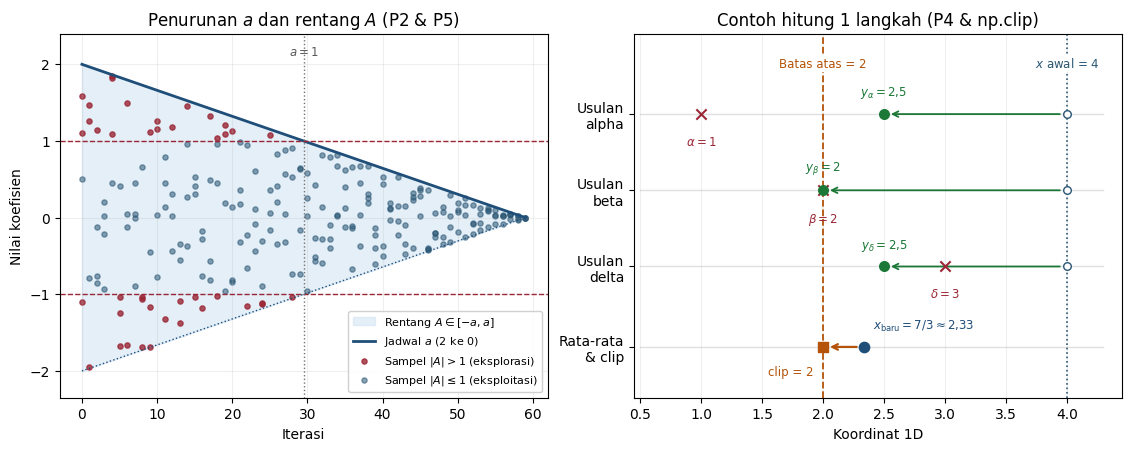

In [4]:
n_steps = 60
steps = np.arange(n_steps)
a_sched = 2 * (1 - steps / (n_steps - 1))
rng_demo = np.random.default_rng(7)
sample_A = a_sched[:, None] * (2 * rng_demo.random((n_steps, 4)) - 1)
sample_t = np.repeat(steps[:, None], 4, axis=1)
far = np.abs(sample_A) > 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.4), layout="constrained")

ax1.fill_between(steps, -a_sched, a_sched, color="#cfe2f3", alpha=0.55, label=r"Rentang $A \in [-a, a]$")
ax1.plot(steps, a_sched, color="#1f4e79", lw=2, label="Jadwal $a$ (2 ke 0)")
ax1.plot(steps, -a_sched, color="#1f4e79", lw=1, ls=":")
ax1.scatter(sample_t[far], sample_A[far], s=14, color="#9b2635", alpha=0.8, label="Sampel $|A| > 1$ (eksplorasi)")
ax1.scatter(sample_t[~far], sample_A[~far], s=14, color="#2a5674", alpha=0.55, label=r"Sampel $|A| \leq 1$ (eksploitasi)")
ax1.axhline(1, color="#9b2635", ls="--", lw=1)
ax1.axhline(-1, color="#9b2635", ls="--", lw=1)
ax1.axvline((n_steps - 1) / 2, color="0.45", ls=":", lw=1)
ax1.text(29.5, 2.08, "$a = 1$", ha="center", va="bottom", fontsize=8.5, color="0.35")
ax1.set(
    xlabel="Iterasi",
    ylabel="Nilai koefisien",
    ylim=(-2.35, 2.4),
    title="Penurunan $a$ dan rentang $A$ (P2 & P5)",
)
ax1.grid(alpha=0.2)
ax1.legend(loc="lower right", fontsize=8, framealpha=0.92)

rows_info = [
    (3.1, 1.0, 2.5, r"$\alpha = 1$", r"$y_\alpha = 2{,}5$"),
    (2.2, 2.0, 2.0, r"$\beta = 2$", r"$y_\beta = 2$"),
    (1.3, 3.0, 2.5, r"$\delta = 3$", r"$y_\delta = 2{,}5$"),
]
ax2.axvline(4.0, color="#2a5674", ls=":", lw=1.2)
ax2.text(4.0, 3.62, "$x$ awal = 4", ha="center", va="bottom", fontsize=8.5, color="#2a5674", bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5})
ax2.axvline(2.0, color="#b45309", ls="--", lw=1.3)
ax2.text(2.0, 3.62, "Batas atas = 2", ha="center", va="bottom", fontsize=8.5, color="#b45309", bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5})

for y_pos, leader_x, prop_x, l_lbl, p_lbl in rows_info:
    ax2.plot([0.5, 4.3], [y_pos, y_pos], color="0.88", lw=1, zorder=1)
    ax2.scatter([leader_x], [y_pos], marker="x", s=55, color="#9b2635", zorder=4)
    ax2.scatter([4.0], [y_pos], s=30, facecolors="white", edgecolors="#2a5674", zorder=3)
    ax2.scatter([prop_x], [y_pos], s=48, color="#1b7837", zorder=5)
    ax2.annotate(
        "",
        xy=(prop_x, y_pos),
        xytext=(4.0, y_pos),
        arrowprops={"arrowstyle": "->", "color": "#1b7837", "lw": 1.3, "shrinkA": 5, "shrinkB": 5},
    )
    ax2.text(leader_x, y_pos - 0.25, l_lbl, ha="center", va="top", fontsize=8.5, color="#9b2635")
    ax2.text(prop_x, y_pos + 0.16, p_lbl, ha="center", va="bottom", fontsize=8.5, color="#1b7837")

y_avg = 0.35
ax2.plot([0.5, 4.3], [y_avg, y_avg], color="0.88", lw=1, zorder=1)
ax2.scatter([7 / 3], [y_avg], s=55, color="#1f4e79", zorder=5)
ax2.scatter([2.0], [y_avg], s=55, marker="s", color="#b45309", zorder=5)
ax2.annotate(
    "",
    xy=(2.0, y_avg),
    xytext=(7 / 3, y_avg),
    arrowprops={"arrowstyle": "->", "color": "#b45309", "lw": 1.6, "shrinkA": 5, "shrinkB": 5},
)
ax2.text(7 / 3 + 0.08, y_avg + 0.16, r"$x_{\mathrm{baru}} = 7/3 \approx 2{,}33$", ha="left", va="bottom", fontsize=8.5, color="#1f4e79")
ax2.text(1.92, y_avg - 0.22, "clip = 2", ha="right", va="top", fontsize=8.5, color="#b45309")

ax2.set(
    xlabel="Koordinat 1D",
    xlim=(0.45, 4.45),
    ylim=(-0.25, 4.05),
    yticks=[0.35, 1.3, 2.2, 3.1],
    yticklabels=["Rata-rata\n& clip", "Usulan\ndelta", "Usulan\nbeta", "Usulan\nalpha"],
    title="Contoh hitung 1 langkah (P4 & np.clip)",
)
ax2.grid(axis="x", alpha=0.2)
plt.show()

## 3. Implementasi NumPy

| Blok | Bagian yang perlu diperhatikan di kode |
| --- | --- |
| P1–P3 | `initial_population` membuat array posisi `(N, d)`. `draw_coefficients(0)` menyiapkan koefisien langkah pertama. `f(positions)` mengembalikan `N` skor untuk memilih tiga pemimpin awal. |
| P4–P5 | `update_positions` menghitung tiga usulan untuk tiap anggota. `draw_coefficients` menyiapkan koefisien langkah berikutnya selama loop belum selesai. |
| P6–P7 | `f(positions)` mengevaluasi populasi baru. `np.concatenate` menggabungkan pemimpin lama dengan populasi baru sebelum diurutkan oleh `np.argsort` (yang mengembalikan urutan indeks dari skor terkecil). |
| P8–P9 | `completed` menghitung iterasi yang selesai, `history` mencatat skor alpha terbaik, dan `snapshots` menyimpan posisi pada iterasi tertentu untuk diplot. Loop berhenti saat `completed == n_iter`. |

Di P4, array `proposals` berbentuk 3D `(3, N, d)` — bisa dibayangkan sebagai tiga tumpukan tabel `(N, d)`, satu tumpukan untuk masing-masing pemimpin ($\alpha, \beta, \delta$). Pemanggilan `mean(axis=0)` merata-ratakan menembus ketiga tumpukan itu sehingga tiap anggota mendapat rata-rata dari tiga usulannya sendiri tanpa tercampur dengan kandidat lain. Pada jalur utama (`leader_archive=True`), `best_position` sama dengan alpha yang dikembalikan di akhir. Variabel `best_position` tetap dicatat terpisah supaya kita bisa melacak rekor terbaik saat menguji pembanding tanpa memori P7 (`leader_archive=False`), di mana alpha aktif bisa memburuk.

In [5]:
def initial_population(n_wolves, dim, bounds, seed):
    return np.random.default_rng(seed).uniform(*bounds, size=(n_wolves, dim))


def movement_coefficients(a, r1, r2):
    return a * (2 * r1 - 1), 2 * r2


def update_positions(positions, leaders, A, C):
    leader_positions = leaders[:, None, :]
    D = np.abs(C * leader_positions - positions)
    proposals = leader_positions - A * D
    return proposals.mean(axis=0)


def gwo_numpy(f, bounds, initial, n_iter, seed, snapshots=(), *, leader_archive=True):
    if len(initial) < 3 or n_iter < 1:
        raise ValueError("GWO perlu minimal 3 anggota dan 1 iterasi.")

    positions = np.clip(initial, *bounds)  # P1
    rng = np.random.default_rng(seed)
    shape = (3, *positions.shape)

    def draw_coefficients(completed):
        a = 2 * (1 - completed / max(1, n_iter - 1))
        return movement_coefficients(a, rng.random(shape), rng.random(shape))

    completed = 0
    A, C = draw_coefficients(completed)  # P2
    fitness = f(positions)  # P3
    order = np.argsort(fitness, kind="stable")[:3]
    leaders, leader_scores = positions[order], fitness[order]
    best_position = leaders[0]
    history = np.empty(n_iter + 1)
    history[0] = leader_scores[0]
    frames = {0: (positions, leaders)} if 0 in snapshots else {}

    while completed < n_iter:  # P9
        positions = np.clip(update_positions(positions, leaders, A, C), *bounds)  # P4
        if completed + 1 < n_iter:  # P5. Jangan undi koefisien yang tidak akan dipakai.
            A, C = draw_coefficients(completed + 1)
        fitness = f(positions)  # P6

        if leader_archive:  # P7
            candidates = np.concatenate((leaders, positions))
            scores = np.concatenate((leader_scores, fitness))
        else:
            candidates, scores = positions, fitness
        order = np.argsort(scores, kind="stable")[:3]
        leaders, leader_scores = candidates[order], scores[order]

        completed += 1  # P8
        history[completed] = history[completed - 1]
        if leader_scores[0] < history[completed]:
            best_position = leaders[0]
            history[completed] = leader_scores[0]
        if completed in snapshots:
            frames[completed] = (positions, leaders)

    return best_position, history, frames

In [6]:
x = np.array([[4.]])
leaders = np.array([[1.], [2.], [3.]])
r1 = np.array([0.25, 0.5, 0.75]).reshape(3, 1, 1)
r2 = np.full_like(r1, 0.5)
A, C = movement_coefficients(1, r1, r2)
position = update_positions(x, leaders, A, C)
np.testing.assert_allclose(position, [[7 / 3]])
print(f"Posisi baru sebelum clip = {position.item():.6f}")

demo_start = np.array([[1.], [2.], [3.], [4.]])
demo_best, demo_history, demo_frames = gwo_numpy(
    sphere, BOUNDS, demo_start, 1, seed=23, snapshots=(0, 1)
)
for t, (population, guide) in demo_frames.items():
    population_scores = sphere(population)
    print(f"Iterasi {t} | posisi = {population.ravel().round(3)}")
    print(f"  Fitness populasi = {population_scores.round(3)}")
    print(f"  Pemimpin = {guide.ravel().round(3)} | f(alpha) = {demo_history[t]:.3f}")
print(f"P9 mengembalikan alpha = {demo_best.item():.3f}")

Posisi baru sebelum clip = 2.333333
Iterasi 0 | posisi = [1. 2. 3. 4.]
  Fitness populasi = [ 1.  4.  9. 16.]
  Pemimpin = [1. 2. 3.] | f(alpha) = 1.000
Iterasi 1 | posisi = [1.28  1.523 3.415 4.269]
  Fitness populasi = [ 1.638  2.321 11.66  18.226]
  Pemimpin = [1.    1.28  1.523] | f(alpha) = 1.000
P9 mengembalikan alpha = 1.000


## 4. Membaca gerak populasi

Sekarang kita jalankan alur slide 13 pada Rastrigin 2D dan amati gerak kawanannya lewat **grafik kontur** (mirip peta ketinggian: satu garis kontur menghubungkan titik-titik dengan nilai $f$ yang sama). Lingkaran menandai posisi populasi aktif, tanda silang merah menandai tiga pemimpin yang tersimpan di memori, dan bintang hijau menandai posisi minimum global $(0,0)$. Karena pemimpin disimpan di P7, tanda silang bisa berada di luar populasi aktif atau tampak bertumpuk saat posisinya berdekatan.

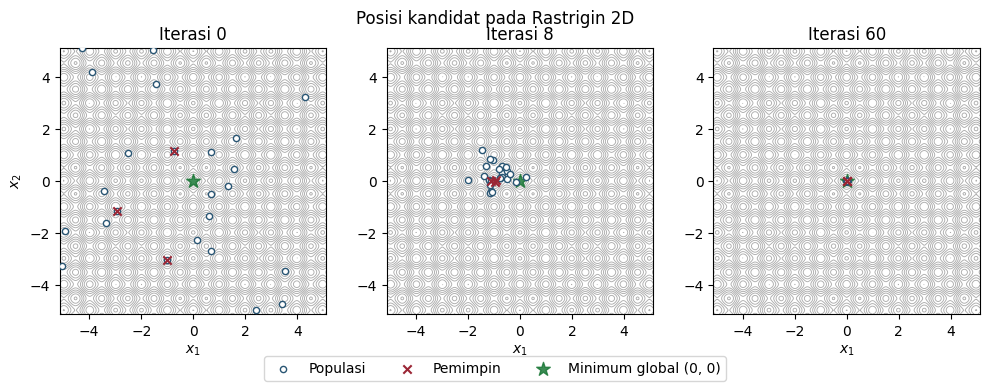

Awal f = 10.6 | Akhir f = 5.229e-28
Posisi terbaik: [-1.10321802e-14 -2.00294848e-14]


In [7]:
checkpoints = (0, 8, 60)
initial_2d = initial_population(24, 2, BOUNDS, seed=17)
best_2d, history_2d, frames = gwo_numpy(
    rastrigin, BOUNDS, initial_2d, n_iter=checkpoints[-1], seed=23, snapshots=checkpoints
)

grid = np.linspace(*BOUNDS, 220)
x_grid, y_grid = np.meshgrid(grid, grid)
landscape = rastrigin(np.stack((x_grid, y_grid), axis=-1))
fig, axes = plt.subplots(1, len(checkpoints), figsize=(10, 3.8), layout="constrained")
fig.suptitle("Posisi kandidat pada Rastrigin 2D")
for ax, t in zip(axes, checkpoints):
    population, guide = frames[t]
    ax.contour(x_grid, y_grid, landscape, levels=18, colors="0.68", linewidths=0.65)
    ax.scatter(*population.T, s=20, facecolors="white", edgecolors="#2a5674", zorder=4, label="Populasi")
    ax.scatter(*guide.T, s=36, marker="x", color="#9b2635", zorder=5, label="Pemimpin")
    ax.scatter([0], [0], s=105, marker="*", color="#1b7837", alpha=0.85, zorder=3, label="Minimum global (0, 0)")
    ax.set(xlabel="$x_1$", xlim=BOUNDS, ylim=BOUNDS, aspect="equal", title=f"Iterasi {t}")
axes[0].set_ylabel("$x_2$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
plt.show()
print(f"Awal f = {history_2d[0]:.4g} | Akhir f = {history_2d[-1]:.4g}")
print("Posisi terbaik:", best_2d)

Pada dimensi tinggi seperti Sphere 10D, ruang pencarian tidak bisa lagi digambar sebagai peta kontur. Sebagai gantinya, kita membaca **kurva konvergensi** dari catatan P8, yaitu perkembangan skor alpha terbaik dari iterasi ke iterasi. Karena P7 tetap mempertimbangkan pemimpin lama, kurva ini tidak pernah naik (selalu turun atau mendatar). Kode di bawah juga memakai `assert` untuk memastikan skor akhir kurva cocok dengan `sphere(best_sphere)` dan selisih antar-iterasi tidak pernah positif, lalu menghitung jarak lurus (norm Euclidean) solusi terhadap titik nol. Ingat, hasil mulus di Sphere (satu lembah) belum menguji kemampuan keluar dari jebakan minimum lokal.

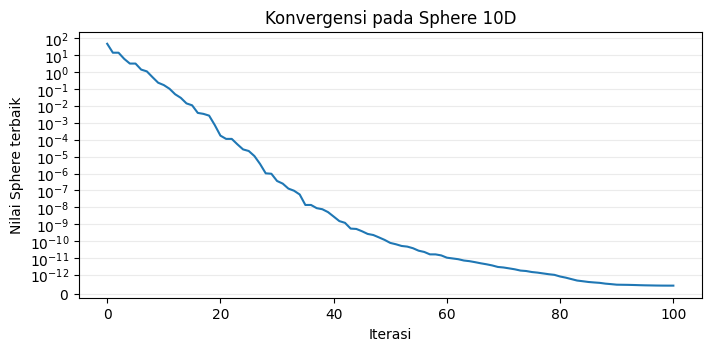

Jarak solusi terbaik dari titik nol: 6.59e-07


In [8]:
initial_10d = initial_population(24, 10, BOUNDS, seed=17)
best_sphere, history_sphere, _ = gwo_numpy(sphere, BOUNDS, initial_10d, n_iter=100, seed=23)
np.testing.assert_allclose(history_sphere[-1], sphere(best_sphere))
assert np.all(np.diff(history_sphere) <= 0)

fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
ax.plot(history_sphere)
ax.set(xlabel="Iterasi", ylabel="Nilai Sphere terbaik", title="Konvergensi pada Sphere 10D")
ax.set_yscale("symlog", linthresh=1e-12)
ax.grid(axis="y", alpha=0.25)
plt.show()
print(f"Jarak solusi terbaik dari titik nol: {np.linalg.norm(best_sphere):.3g}")

## 5. Di blok mana modifikasi masuk?

Banyak variasi GWO — termasuk di library siap pakai — memodifikasi bagian tertentu dari alur dasar tanpa menyentuh rumus gerak P4. Memakai label P1–P9 yang sama, tabel di bawah memetakan titik masuk tiap perubahan. Untuk menguji efek satu perubahan secara adil, ubah satu blok saja sementara populasi awal, seed, dan budget evaluasi dijaga tetap.

| Modifikasi atau tambahan | Titik pemasangan | Perubahan yang terjadi |
| --- | --- | --- |
| Batas koordinat | **Sesudah P4, sebelum P6** | `np.clip` memotong koordinat yang keluar batas sebelum diberi skor. Ini berbeda dari penalti untuk kendala yang melibatkan hubungan antar koordinat. |
| Tanpa memori pemimpin | **Di P7, setelah P6** | Set `leader_archive=False` supaya pemimpin hanya dipilih dari populasi baru tanpa melibatkan pemimpin lama. Dipakai sebagai pembanding, bukan alur utama slide. |
| Seleksi *greedy* MEALPY 3.0.3 | **Di antara P6 dan P7** | Untuk tiap anggota, skor usulan baru dibandingkan dengan skor posisi lamanya; hanya yang lebih baik yang dipertahankan. Tiga pemimpin iterasi berikutnya dipilih dari populasi hasil seleksi ini. |
| Jadwal $a$ MEALPY 3.0.3 | **Di P2 dan P5** | Gerakan $t=1,\ldots,T$ memakai $a=2(1-t/T)$. Untuk $T>1$, langkah pertama sudah mulai sedikit di bawah $2$ dan tetap berakhir di $0$. |
| Penalti kendala | **Di fungsi tujuan P3 dan P6** | Kandidat yang melanggar syarat ditambah skor hukuman besar sebelum diurutkan. Rumus gerak P4 tidak diubah. |

Grafik kontur dan kurva konvergensi hanya membaca catatan P8; keduanya tidak ikut memengaruhi posisi baru.

### Menggunakan library MEALPY

Saat memakai MEALPY, kita tidak perlu menulis loop GWO manual — cukup definisikan masalahnya di dictionary `problem`. `FloatVar` mengatur batas bawah dan atas untuk tiap koordinat bertipe float, `minmax="min"` memilih minimisasi, dan `obj_func` menerima satu kandidat lalu mengembalikan satu angka skor. Parameter `epoch` menyatakan jumlah iterasi dan `pop_size` menyatakan ukuran populasi. Setelah `solve()`, ambil posisi terbaik dari `best.solution` dan skornya dari `best.target.fitness`. Wrapper `run_mealpy` di bawah juga menghitung `calls` supaya jumlah evaluasi kandidatnya tercatat pasti.

In [9]:
def run_mealpy(f, bounds, initial, n_iter, seed):
    dim = initial.shape[1]
    lo, hi = (np.broadcast_to(bound, (dim,)) for bound in bounds)
    calls = 0

    def objective(x):
        nonlocal calls
        calls += 1
        return float(f(x))

    problem = {
        "bounds": FloatVar(lb=lo, ub=hi, name="x"),
        "minmax": "min",
        "obj_func": objective,
        "log_to": None,
    }
    model = GWO.OriginalGWO(epoch=n_iter, pop_size=len(initial))
    best = model.solve(problem, mode="swarm", starting_solutions=initial, seed=seed)
    return best, calls


best_library, calls = run_mealpy(sphere, BOUNDS, initial_10d, n_iter=100, seed=23)
print(np.array2string(best_library.solution, precision=3))
print(f"Nilai Sphere = {best_library.target.fitness:.6g} | Evaluasi kandidat = {calls}")

[ 1.166e-06  1.220e-06 -1.002e-06 -1.259e-06  1.193e-06  9.974e-07
 -9.491e-07  8.595e-07 -1.082e-06  1.063e-06]
Nilai Sphere = 1.17937e-11 | Evaluasi kandidat = 2424


## 6. Uji implementasi pada Rastrigin 10D

Karena gerak GWO acak, satu kali run pada Rastrigin 10D belum cukup untuk membandingkan performa. Di sini kita ulang percobaan memakai **10 seed** (angka awal untuk random generator supaya urutan acaknya bisa diulang). Di tiap seed, ketiga versi menerima 24 posisi awal yang sama persis dan berjalan 80 iterasi. Dua versi NumPy memakai seed gerak dan jadwal $a$ yang sama sehingga selisih hasilnya langsung mencerminkan efek memori P7. Sementara MEALPY berbeda sekaligus pada seleksi *greedy*, jadwal $a$, dan urutan pengacakannya, jadi selisih dengan MEALPY tidak bisa disimpulkan murni berasal dari seleksi *greedy* saja.

Agar adil, **budget evaluasi** disamakan menjadi $N(T+1)=1.944$ kandidat per run. Yang dihitung adalah jumlah kandidat yang dievaluasi, bukan berapa kali fungsi Python dipanggil — NumPy mengevaluasi 24 kandidat sekaligus dalam satu panggilan array, sedangkan di MEALPY kita hitung tiap panggilan `obj_func`. Hasil 10 ulangan dirangkum memakai **median** (nilai tengah yang tidak mudah tertarik oleh outlier ekstrem) dan rentang kuartil **Q1–Q3** (sebaran 50% hasil bagian tengah), lalu divisualisasikan lewat boxplot beserta titik tiap seed. Satu fungsi dan satu budget tetap belum menentukan pemenang umum.

Slide 15–16 merangkum benchmark dari paper aslinya, termasuk perbandingan GWO dengan PSO dan metode lain. Praktikum ini menjalankan eksperimen sendiri untuk tiga versi implementasi GWO, bukan menyalin ulang tabel paper. Implementasi PSO di repo ini tetap bisa dijadikan pembanding asalkan fungsi uji, batas, dimensi, dan budget evaluasinya disamakan.

| Implementasi | Median f | Q1 | Q3 | Evaluasi per ulangan |
| --- | ---: | ---: | ---: | ---: |
| NumPy (alur slide) | 7.892 | 6.171 | 9.99 | 1944 |
| NumPy tanpa memori P7 | 4.472 | 3.678 | 5.138 | 1944 |
| MEALPY 3.0.3 | 8.628 | 6.257 | 13.1 | 1944 |

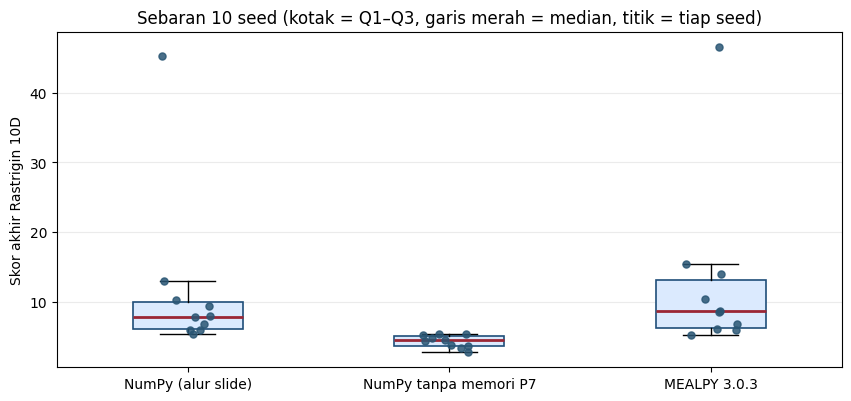

In [10]:
n_wolves, dim, n_iter = 24, 10, 80
seeds = range(10)
scores = {"NumPy (alur slide)": [], "NumPy tanpa memori P7": [], "MEALPY 3.0.3": []}
evaluations = {name: set() for name in scores}

for seed in seeds:
    initial = initial_population(n_wolves, dim, BOUNDS, seed)
    movement_seed = 1000 + seed
    for name, use_archive in (("NumPy (alur slide)", True), ("NumPy tanpa memori P7", False)):
        _, curve, _ = gwo_numpy(
            rastrigin, BOUNDS, initial, n_iter, movement_seed, leader_archive=use_archive
        )
        scores[name].append(curve[-1])
        evaluations[name].add(n_wolves * (n_iter + 1))
    best, calls = run_mealpy(rastrigin, BOUNDS, initial, n_iter, movement_seed)
    scores["MEALPY 3.0.3"].append(best.target.fitness)
    evaluations["MEALPY 3.0.3"].add(calls)

rows = [
    "| Implementasi | Median f | Q1 | Q3 | Evaluasi per ulangan |",
    "| --- | ---: | ---: | ---: | ---: |",
]
for name, values in scores.items():
    q1, median, q3 = np.quantile(values, (0.25, 0.5, 0.75))
    budgets = ", ".join(str(n) for n in sorted(evaluations[name]))
    rows.append(f"| {name} | {median:.4g} | {q1:.4g} | {q3:.4g} | {budgets} |")
display(Markdown("\n".join(rows)))

labels = list(scores.keys())
data = [scores[name] for name in labels]
fig, ax = plt.subplots(figsize=(8.4, 3.9), layout="constrained")
bp = ax.boxplot(data, widths=0.42, patch_artist=True, showfliers=False)
for box in bp["boxes"]:
    box.set(facecolor="#dbeafe", edgecolor="#1f4e79", linewidth=1.2)
for median_line in bp["medians"]:
    median_line.set(color="#9b2635", linewidth=2)
rng_plot = np.random.default_rng(0)
for idx, vals in enumerate(data, start=1):
    jitter = rng_plot.uniform(-0.1, 0.1, size=len(vals))
    ax.scatter(np.full(len(vals), idx) + jitter, vals, s=26, color="#2a5674", alpha=0.85, zorder=4)
ax.set_xticks(range(1, len(labels) + 1))
ax.set_xticklabels(labels)
ax.set(
    ylabel="Skor akhir Rastrigin 10D",
    title="Sebaran 10 seed (kotak = Q1–Q3, garis merah = median, titik = tiap seed)",
)
ax.grid(axis="y", alpha=0.25)
plt.show()

## 7. Terapkan penalti pada masalah berkendala

Slide 17 menangani **kendala** (*constraint*) dengan memberi skor hukuman yang besar pada kandidat yang melanggar aturan. Alih-alih langsung meniru kasus desain teknik seperti pegas, balok las, atau bejana tekan, kita pakai contoh 2D sederhana supaya solusi eksaknya mudah dicek.

Masalahnya: minimalkan $f(x)=x_1^2+x_2^2$ dengan batas koordinat $x_1,x_2\in[0,2]$ dan syarat tambahan $x_1+x_2\ge1$. `np.clip` hanya bisa menjaga batas tiap koordinat satu per satu. Untuk syarat jumlah ini, **ganti fungsi tujuan di P3 dan P6** dengan menambahkan penalti sebesar 10 setiap kali kandidat melanggar. Di kotak $[0,2]^2$, skor Sphere maksimal hanya $8$, jadi kandidat yang melanggar (skor minimal $10$) pasti kalah peringkat dibanding kandidat mana pun yang **layak** (*feasible*). Nilai 10 ini cocok untuk skala contoh ini saja; pada fungsi tujuan dengan skala lain, besar penaltinya harus disesuaikan.

Tanpa kendala jumlah, Sphere mencapai nilai terendah $0$ di $(0,0)$, tapi titik itu melanggar syarat ($0+0<1$). **Solusi analitis** yang layak ada di $(0{,}5; 0{,}5)$ dengan skor asli $0{,}5$. Setelah `solve()`, cek **kelayakan** dan **nilai tujuan asli** (tanpa penalti) secara terpisah, lalu amati perubahan peta skornya pada grafik dua panel di bawah.

| Kandidat | Sphere | Skor setelah penalti |
| --- | ---: | ---: |
| [0.0, 0.0] | 0 | 10 |
| [0.5, 0.5] | 0.5 | 0.5 |
| [1.0, 1.0] | 2 | 2 |

Posisi = [0.50266856 0.49739434] | x1 + x2 = 1.000063
Layak? True | f tanpa penalti = 0.500077


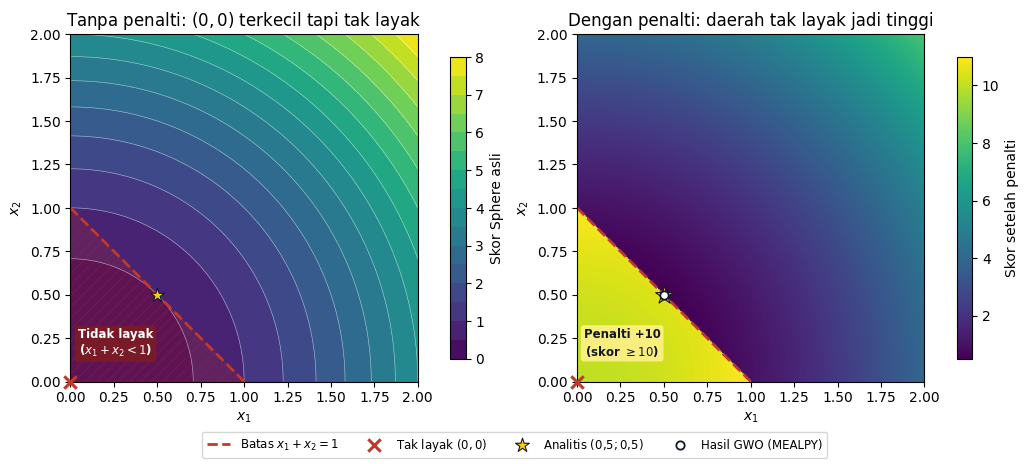

In [11]:
constraint_bounds = (0., 2.)


def penalized_sphere(x, minimum_sum=1.):
    violates = np.sum(x, axis=-1) < minimum_sum
    return sphere(x) + 10. * violates


probe = np.array([[0., 0.], [0.5, 0.5], [1., 1.]])
display(Markdown(
    "| Kandidat | Sphere | Skor setelah penalti |\n| --- | ---: | ---: |\n"
    + "\n".join(
        f"| {point.tolist()} | {raw:g} | {score:g} |"
        for point, raw, score in zip(probe, sphere(probe), penalized_sphere(probe))
    )
))

constrained_start = initial_population(24, 2, constraint_bounds, seed=17)
constrained_best, _ = run_mealpy(
    penalized_sphere, constraint_bounds, constrained_start, n_iter=100, seed=23
)

point = constrained_best.solution
print(f"Posisi = {point} | x1 + x2 = {point.sum():.6f}")
print(f"Layak? {point.sum() >= 1.} | f tanpa penalti = {sphere(point):.6f}")

u_c = np.linspace(*constraint_bounds, 240)
c_x1, c_x2 = np.meshgrid(u_c, u_c)
c_grid = np.stack((c_x1, c_x2), axis=-1)
raw_map = sphere(c_grid)
pen_map = penalized_sphere(c_grid)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.2, 4.5), layout="constrained")

cf1 = ax1.contourf(c_x1, c_x2, raw_map, levels=16, cmap="viridis")
ax1.contour(c_x1, c_x2, raw_map, levels=16, colors="white", linewidths=0.45, alpha=0.55)
ax1.fill([0, 1, 0], [0, 0, 1], facecolor="#9b2635", alpha=0.28, hatch="///", edgecolor="#9b2635")
ax1.plot([0, 1], [1, 0], color="#c0392b", ls="--", lw=2, label="Batas $x_1+x_2=1$")
ax1.scatter([0], [0], marker="x", s=80, color="#c0392b", linewidths=2.2, zorder=8, clip_on=False, label="Tak layak $(0,0)$")
ax1.scatter([0.5], [0.5], marker="*", s=110, color="#facc15", edgecolors="#111827", linewidths=0.8, zorder=6, label="Analitis $(0{,}5; 0{,}5)$")
ax1.text(
    0.26, 0.22, "Tidak layak\n($x_1+x_2<1$)", fontsize=8.5, color="white", weight="bold", ha="center", va="center",
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "#7f1d1d", "alpha": 0.8, "edgecolor": "none"},
)
ax1.set(
    xlabel="$x_1$", ylabel="$x_2$", xlim=constraint_bounds, ylim=constraint_bounds, aspect="equal",
    title="Tanpa penalti: $(0,0)$ terkecil tapi tak layak",
)
fig.colorbar(cf1, ax=ax1, shrink=0.84, label="Skor Sphere asli")

im2 = ax2.imshow(pen_map, origin="lower", extent=(*constraint_bounds, *constraint_bounds), cmap="viridis", aspect="equal")
ax2.plot([0, 1], [1, 0], color="#c0392b", ls="--", lw=2)
ax2.scatter([0], [0], marker="x", s=80, color="#c0392b", linewidths=2.2, zorder=8, clip_on=False)
ax2.scatter([0.5], [0.5], marker="*", s=180, color="#facc15", edgecolors="#111827", linewidths=0.8, zorder=6)
ax2.scatter([point[0]], [point[1]], s=36, facecolors="white", edgecolors="#111827", linewidths=1.3, zorder=7, label="Hasil GWO (MEALPY)")
ax2.text(
    0.26, 0.22, "Penalti +10\n(skor $\\geq 10$)", fontsize=8.5, color="#111827", weight="bold", ha="center", va="center",
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "#fef08a", "alpha": 0.9, "edgecolor": "none"},
)
ax2.set(
    xlabel="$x_1$", ylabel="$x_2$", xlim=constraint_bounds, ylim=constraint_bounds, aspect="equal",
    title="Dengan penalti: daerah tak layak jadi tinggi",
)
fig.colorbar(im2, ax=ax2, shrink=0.84, label="Skor setelah penalti")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="outside lower center", ncol=4, fontsize=8.5)
plt.show()

## Latihan soal

### 1. Hitung kasus $a=0$

Pakai posisi awal, tiga pemimpin, dan angka acak dari contoh satu koordinat di Bagian 2. Hitung posisi baru di P4 saat $a=0$, lalu cocokkan hasilnya memakai `movement_coefficients` dan `update_positions`. Jelaskan kenapa posisi awal serigala tidak lagi memengaruhi hasil sebelum `np.clip`.

In [12]:
# Saat a = 0, semua A bernilai 0 sehingga suku A*D hilang.
A_nol, C_nol = movement_coefficients(0, r1, r2)
posisi_nol = update_positions(x, leaders, A_nol, C_nol)
print("Hasil update_positions :", posisi_nol.item())
print("Rata-rata tiga pemimpin:", leaders.mean())

# Cek ulang dengan posisi awal yang sangat berbeda: hasilnya harus tetap sama.
for awal in (-3., 0.5, 4.):
    hasil = update_positions(np.array([[awal]]), leaders, A_nol, C_nol).item()
    print(f"Posisi awal {awal:>4} -> {hasil}")
    assert np.isclose(hasil, leaders.mean())

# Penjelasan singkat.
penjelasan_nol = (
    "Rumus gerak tiap usulan adalah posisi pemimpin dikurangi A*D. Posisi awal serigala hanya "
    "masuk lewat D, tetapi saat a = 0 nilai A ikut menjadi 0, jadi suku A*D hilang. Yang tersisa "
    "hanya posisi pemimpin, sehingga ketiga usulan jatuh tepat di alpha, beta, dan delta "
    "(1, 2, 3). Posisi baru adalah rata-ratanya, yaitu 2, siapa pun posisi awalnya."
)
print(penjelasan_nol)


Hasil update_positions : 2.0
Rata-rata tiga pemimpin: 2.0
Posisi awal -3.0 -> 2.0
Posisi awal  0.5 -> 2.0
Posisi awal  4.0 -> 2.0
Rumus gerak tiap usulan adalah posisi pemimpin dikurangi A*D. Posisi awal serigala hanya masuk lewat D, tetapi saat a = 0 nilai A ikut menjadi 0, jadi suku A*D hilang. Yang tersisa hanya posisi pemimpin, sehingga ketiga usulan jatuh tepat di alpha, beta, dan delta (1, 2, 3). Posisi baru adalah rata-ratanya, yaitu 2, siapa pun posisi awalnya.


<details>
<summary>Pembahasan soal 1</summary>

Saat $a=0$, seluruh komponen $A_k$ menjadi $0$. Walaupun $D_k$ masih bergantung pada posisi awal serigala, suku $A_kD_k$ hilang karena dikalikan nol. Akibatnya, ketiga usulan tepat berada di posisi pemimpin ($1, 2, 3$) dan posisi barunya selalu rata-rata ketiga pemimpin, yaitu $(1+2+3)/3=2$.

```python
A_zero, C_zero = movement_coefficients(0, r1, r2)
position_at_zero = update_positions(x, leaders, A_zero, C_zero)
print(position_at_zero.item())
```

</details>

### 2. Atur ukuran populasi dengan budget evaluasi tetap

Pada Rastrigin 10D, bandingkan jalur utama GWO NumPy dengan ukuran populasi $N=12$ dan $N=24$. Sesuaikan jumlah iterasi $T$ (P9) supaya masing-masing mengevaluasi tepat 1.944 kandidat per run. Pakai `seeds` yang sama dengan percobaan utama, lalu bandingkan median dan rentang Q1–Q3. Jelaskan trade-off antara banyaknya kandidat yang dicoba per iterasi dengan banyaknya kesempatan memperbarui pemimpin (P7).

In [13]:
# Budget tetap 1944 evaluasi. Populasi awal sudah memakai satu putaran evaluasi, jadi T = 1944/N - 1.
budget = 1944
for ukuran in (12, 24):
    iterasi = budget // ukuran - 1
    skor_akhir = []
    for seed in seeds:
        awal = initial_population(ukuran, 10, BOUNDS, seed)
        _, kurva, _ = gwo_numpy(rastrigin, BOUNDS, awal, iterasi, 1000 + seed)
        skor_akhir.append(kurva[-1])
    q1, median, q3 = np.quantile(skor_akhir, (0.25, 0.5, 0.75))
    print(f"N={ukuran}, T={iterasi}, evaluasi={ukuran * (iterasi + 1)}, "
          f"median={median:.4g}, Q1-Q3={q1:.4g} - {q3:.4g}")

penjelasan_populasi = (
    "Dengan budget yang sama, N=12 (161 iterasi) dan N=24 (80 iterasi) hasilnya mirip: median 7,51 vs 7,89. "
    "N=12 sedikit lebih unggul dan kadang jauh lebih bagus (Q1 2,55 vs 6,17), tetapi sebarannya juga lebih lebar. "
    "Populasi kecil mencoba lebih sedikit titik per langkah, namun punya dua kali lebih banyak kesempatan "
    "memperbarui pemimpin, jadi kawanan lebih cepat menyempit ke lembah yang menjanjikan, dengan risiko "
    "terkunci di lembah yang salah. Populasi besar menyebar lebih luas sehingga lebih stabil, tetapi iterasinya "
    "singkat dan pemimpinnya jarang diperbarui. Selisihnya kecil, jadi belum ada pemenang yang jelas pada 10 seed."
)
print(penjelasan_populasi)


N=12, T=161, evaluasi=1944, median=7.506, Q1-Q3=2.548 - 9.152
N=24, T=80, evaluasi=1944, median=7.892, Q1-Q3=6.171 - 9.99
Dengan budget yang sama, N=12 (161 iterasi) dan N=24 (80 iterasi) hasilnya mirip: median 7,51 vs 7,89. N=12 sedikit lebih unggul dan kadang jauh lebih bagus (Q1 2,55 vs 6,17), tetapi sebarannya juga lebih lebar. Populasi kecil mencoba lebih sedikit titik per langkah, namun punya dua kali lebih banyak kesempatan memperbarui pemimpin, jadi kawanan lebih cepat menyempit ke lembah yang menjanjikan, dengan risiko terkunci di lembah yang salah. Populasi besar menyebar lebih luas sehingga lebih stabil, tetapi iterasinya singkat dan pemimpinnya jarang diperbarui. Selisihnya kecil, jadi belum ada pemenang yang jelas pada 10 seed.


<details>
<summary>Pembahasan soal 2</summary>

Karena satu putaran evaluasi terpakai untuk populasi awal, gunakan $T=1944/N-1$. Untuk $N=12$ jalankan 161 iterasi, sedangkan untuk $N=24$ jalankan 80 iterasi. Populasi kecil mencoba lebih sedikit titik per langkah, tapi punya lebih banyak iterasi untuk memperbarui pemimpin. Populasi besar menyebar lebih banyak titik di awal dan di tiap langkah, tapi iterasinya lebih pendek. Pakai hasil median dan Q1–Q3 dari 10 seed untuk melihat mana yang lebih membantu dalam kondisi ini.

```python
for size in (12, 24):
    steps = 1944 // size - 1
    final_scores = []
    for seed in seeds:
        start = initial_population(size, 10, BOUNDS, seed)
        _, curve, _ = gwo_numpy(rastrigin, BOUNDS, start, steps, 1000 + seed)
        final_scores.append(curve[-1])
    q1, median, q3 = np.quantile(final_scores, (0.25, 0.5, 0.75))
    print(f"N={size}, T={steps}, median={median:.4g}, Q1–Q3={q1:.4g}–{q3:.4g}")
```

</details>

### 3. Perketat syarat kendala tanpa mengubah rumus gerak

Pakai contoh berkendala di Bagian 7, tapi naikkan syarat jumlahnya menjadi $x_1+x_2\ge 1{,}5$. Ubah fungsi tujuan yang dikirim ke MEALPY sambil mempertahankan seed, populasi awal, dan jumlah iterasi yang sama. Cek apakah hasil akhirnya layak, lalu bandingkan skor asli tanpa penalti dengan solusi analitis yang baru.

In [14]:
# Syarat diperketat jadi x1 + x2 >= 1,5. Rumus gerak tidak diubah, hanya fungsi tujuannya.
batas_jumlah = 1.5
hasil_ketat, _ = run_mealpy(
    lambda x: penalized_sphere(x, batas_jumlah),
    constraint_bounds, constrained_start, n_iter=100, seed=23
)
titik = hasil_ketat.solution
print(f"Posisi = {titik} | x1 + x2 = {titik.sum():.6f}")
print(f"Layak? {titik.sum() >= batas_jumlah} | f tanpa penalti = {sphere(titik):.6f}")
print(f"Acuan analitis (0,75; 0,75) = {batas_jumlah**2 / 2:.6f}")

penjelasan_kendala = (
    "Hasilnya layak: x1 + x2 = 1,5003, dan skor aslinya 1,1258, nyaris sama dengan acuan analitis 1,125 di (0,75; 0,75). "
    "Rumus gerak tidak disentuh sama sekali, cukup fungsi tujuannya yang diberi penalti saat syarat dilanggar. "
    "Hasilnya mendekati batas karena di sanalah skor Sphere paling kecil yang masih lolos penalti."
)
print(penjelasan_kendala)


Posisi = [0.76183362 0.73848895] | x1 + x2 = 1.500323
Layak? True | f tanpa penalti = 1.125756
Acuan analitis (0,75; 0,75) = 1.125000
Hasilnya layak: x1 + x2 = 1,5003, dan skor aslinya 1,1258, nyaris sama dengan acuan analitis 1,125 di (0,75; 0,75). Rumus gerak tidak disentuh sama sekali, cukup fungsi tujuannya yang diberi penalti saat syarat dilanggar. Hasilnya mendekati batas karena di sanalah skor Sphere paling kecil yang masih lolos penalti.


<details>
<summary>Pembahasan soal 3</summary>

Rumus gerak P4 tidak perlu diubah; cukup kirim `minimum_sum=1.5` ke fungsi tujuan P3 dan P6. Untuk jumlah koordinat yang tetap, jumlah kuadrat paling kecil dicapai saat kedua koordinat sama besar, sehingga solusi analitis barunya ada di $(0{,}75; 0{,}75)$ dengan nilai tujuan asli $1{,}125$.

```python
minimum_sum = 1.5
best_stricter, _ = run_mealpy(
    lambda x: penalized_sphere(x, minimum_sum),
    constraint_bounds, constrained_start, n_iter=100, seed=23
)
point = best_stricter.solution
print(f"Posisi = {point} | x1 + x2 = {point.sum():.6f}")
print(f"Layak? {point.sum() >= minimum_sum} | f tanpa penalti = {sphere(point):.6f}")
print(f"Acuan analitis = {minimum_sum**2 / 2:.6f}")
```

</details>

## Referensi

Acuan utama kuliah: `GWO_Materi_Kuliah.pdf` (*Grey Wolf Optimizer (GWO)*) — slide 9–12 untuk persamaan gerak dan koefisien, slide 13 untuk pseudocode, slide 15–16 untuk konteks benchmark, dan slide 17 untuk teknik penalti kendala.

1. Mirjalili, S., Mirjalili, S. M., & Lewis, A. (2014). [Grey Wolf Optimizer](https://doi.org/10.1016/j.advengsoft.2013.12.007). *Advances in Engineering Software*, 69, 46–61. Bagian 3.2 memuat model gerak, jadwal penurunan $a$, dan pseudocode.
2. MEALPY. [Rilis 3.0.3](https://pypi.org/project/mealpy/3.0.3/) dan [kode sumber `OriginalGWO` pada tag v3.0.3](https://github.com/thieu1995/mealpy/blob/v3.0.3/mealpy/swarm_based/GWO.py). Acuan untuk API dan aturan seleksi yang dipakai pada bagian 5–6.
3. Repo praktikum, `Evolutionary Computation/01 - Particle Swarm Optimization.ipynb` dan `Evolutionary Computation/pso_lib.py`. Acuan untuk fungsi Sphere dan Rastrigin, perbandingan cara gerak, dan eksperimen beberapa seed.